In [ ]:
# ## 1. Setup / libraries
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ML Models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Time Series Models
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

plt.style.use('seaborn-v0_8-whitegrid')

In [14]:
# ## 2. Load Data
DATA_PATH = '../data/processed/'
FILE_NAME = 'weather_history_hourly.csv'

df = pd.read_csv(f'{DATA_PATH}{FILE_NAME}')

df['datetime'] = pd.to_datetime(df['datetime'])
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['location', 'datetime']).reset_index(drop=True)

print(f"Rows: {df.shape[0]:,}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Locations: {df['location'].unique().tolist()}")

Rows: 263,160
Date range: 2020-01-01 to 2026-01-01
Locations: ['Birmingham', 'Cardiff', 'Edinburgh', 'London', 'Manchester']


In [15]:
# ## 3. Feature Engineering
# Time features
df['day_of_year'] = df['datetime'].dt.dayofyear
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Lag features
df['temp_lag_1h'] = df.groupby('location')['temperature_2m'].shift(1)
df['temp_lag_24h'] = df.groupby('location')['temperature_2m'].shift(24)
df['temp_lag_168h'] = df.groupby('location')['temperature_2m'].shift(168)

# Rolling features
df['temp_rolling_24h'] = df.groupby('location')['temperature_2m'].transform(
    lambda x: x.rolling(24, min_periods=1).mean()
)

# Encode location
le = LabelEncoder()
df['location_encoded'] = le.fit_transform(df['location'])

# Drop rows with NaN from lag features
df = df.dropna(subset=['temp_lag_168h'])

print(f"Rows after feature engineering: {df.shape[0]:,}")


Rows after feature engineering: 262,320


In [16]:
# ## 4. Train/Test Split
split_date = df['date'].max() - timedelta(days=7)

train = df[df['date'] <= split_date].copy()
test = df[df['date'] > split_date].copy()

print(f"Train: {train.shape[0]:,} rows ({train['date'].min().date()} to {train['date'].max().date()})")
print(f"Test: {test.shape[0]:,} rows ({test['date'].min().date()} to {test['date'].max().date()})")


Train: 261,480 rows (2020-01-08 to 2025-12-25)
Test: 840 rows (2025-12-26 to 2026-01-01)


In [17]:
# ## 5. Define Features
target = 'temperature_2m'

feature_cols = [
    'hour', 'month', 'day_of_year',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    'location_encoded',
    'temp_lag_1h', 'temp_lag_24h', 'temp_lag_168h',
    'temp_rolling_24h',
    'relative_humidity_2m'
]

feature_cols = [col for col in feature_cols if col in df.columns]

X_train = train[feature_cols]
y_train = train[target]
X_test = test[feature_cols]
y_test = test[target]

print(f"Features: {len(feature_cols)}")
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

Features: 13
X_train: (261480, 13), X_test: (840, 13)


In [35]:
# ## 6. ML Models
results = {}

def evaluate(name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    results[name] = {
        'model': model,
        'predictions': y_pred,
        'mae': mean_absolute_error(y_test, y_pred),
        'rmse': np.sqrt(mean_squared_error(y_test, y_pred)),
        'r2': r2_score(y_test, y_pred)
    }
    
    print(f"{name}: MAE={results[name]['mae']:.2f}°C, R²={results[name]['r2']:.3f}")
    
# ### 6.1 Linear Regression
evaluate('Linear Regression', LinearRegression())

# ### 6.2 Ridge Regression
evaluate('Ridge Regression', Ridge(alpha=1.0))

# ### 6.3 Decision Tree
evaluate('Decision Tree', DecisionTreeRegressor(max_depth=10, random_state=42))

# ### 6.4 Random Forest
evaluate('Random Forest', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))

# ### 6.5 Gradient Boosting
evaluate('Gradient Boosting', GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42))

# ### 6.6 XGBoost
evaluate('XGBoost', XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42))

# ### 6.7 LightGBM
evaluate('LightGBM', LGBMRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1))

Linear Regression: MAE=0.42°C, R²=0.931
Ridge Regression: MAE=0.42°C, R²=0.931
Decision Tree: MAE=0.32°C, R²=0.955
Random Forest: MAE=0.30°C, R²=0.961
Gradient Boosting: MAE=0.31°C, R²=0.960
XGBoost: MAE=0.30°C, R²=0.961
LightGBM: MAE=0.30°C, R²=0.961


In [20]:
# ## 7. Time Series Models
# ### 7.1 SARIMA

sarima_predictions = []
sarima_actuals = []

for location in df['location'].unique():
    loc_df = df[df['location'] == location].set_index('datetime')
    daily = loc_df['temperature_2m'].resample('D').mean()
    
    train_ts = daily[daily.index <= split_date]
    test_ts = daily[daily.index > split_date]
    
    model = SARIMAX(train_ts, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7))
    fitted = model.fit(disp=False)
    forecast = fitted.forecast(steps=len(test_ts))
    
    sarima_predictions.extend(forecast.values)
    sarima_actuals.extend(test_ts.values)

results['SARIMA'] = {
    'mae': mean_absolute_error(sarima_actuals, sarima_predictions),
    'rmse': np.sqrt(mean_squared_error(sarima_actuals, sarima_predictions)),
    'r2': r2_score(sarima_actuals, sarima_predictions),
    'predictions': sarima_predictions
}

print(f"SARIMA: MAE={results['SARIMA']['mae']:.2f}°C, R²={results['SARIMA']['r2']:.3f}")


SARIMA: MAE=1.41°C, R²=-0.524


In [21]:
# ### 7.2 Prophet
prophet_predictions = []
prophet_actuals = []

for location in df['location'].unique():
    loc_df = df[df['location'] == location][['datetime', 'temperature_2m']].copy()
    loc_df.columns = ['ds', 'y']
    loc_df = loc_df.set_index('ds').resample('D').mean().reset_index()
    
    train_ts = loc_df[loc_df['ds'] <= split_date]
    test_ts = loc_df[loc_df['ds'] > split_date]
    
    model = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
    model.fit(train_ts)
    
    future = model.make_future_dataframe(periods=len(test_ts))
    forecast = model.predict(future)
    
    preds = forecast.tail(len(test_ts))['yhat'].values
    prophet_predictions.extend(preds)
    prophet_actuals.extend(test_ts['y'].values)

results['Prophet'] = {
    'mae': mean_absolute_error(prophet_actuals, prophet_predictions),
    'rmse': np.sqrt(mean_squared_error(prophet_actuals, prophet_predictions)),
    'r2': r2_score(prophet_actuals, prophet_predictions),
    'predictions': prophet_predictions
}

print(f"Prophet: MAE={results['Prophet']['mae']:.2f}°C, R²={results['Prophet']['r2']:.3f}")


19:59:13 - cmdstanpy - INFO - Chain [1] start processing
19:59:17 - cmdstanpy - INFO - Chain [1] done processing
19:59:17 - cmdstanpy - INFO - Chain [1] start processing
19:59:17 - cmdstanpy - INFO - Chain [1] done processing
19:59:18 - cmdstanpy - INFO - Chain [1] start processing
19:59:18 - cmdstanpy - INFO - Chain [1] done processing
19:59:19 - cmdstanpy - INFO - Chain [1] start processing
19:59:19 - cmdstanpy - INFO - Chain [1] done processing
19:59:19 - cmdstanpy - INFO - Chain [1] start processing
19:59:20 - cmdstanpy - INFO - Chain [1] done processing


Prophet: MAE=3.28°C, R²=-5.021


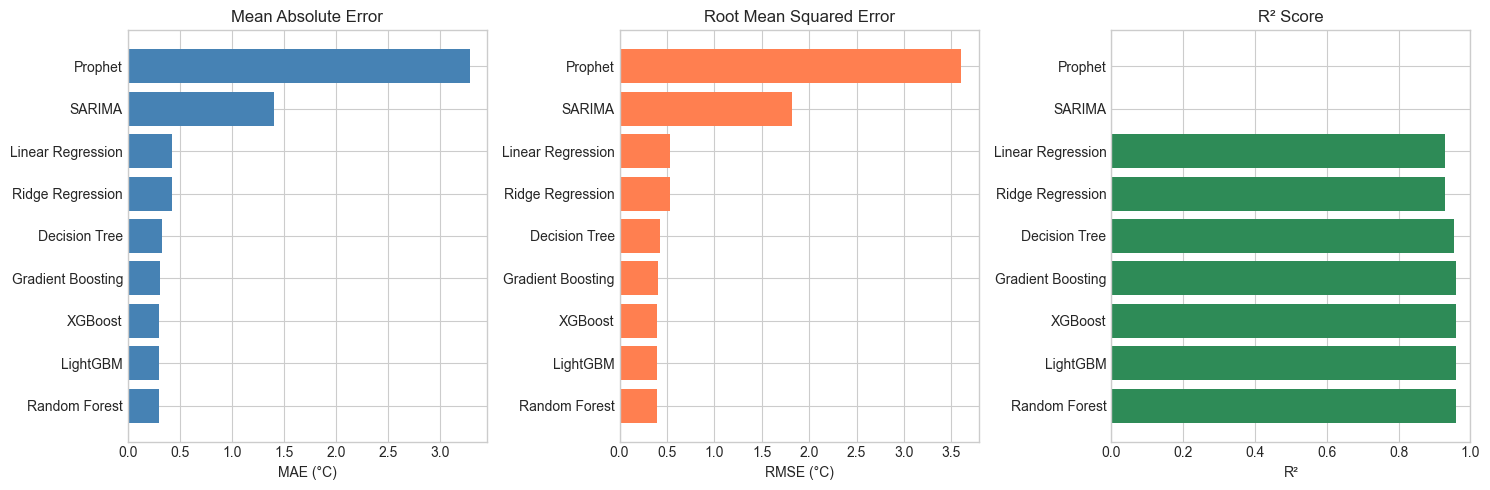

In [22]:
# ## 8. Model Comparison
comparison = pd.DataFrame({
    'Model': results.keys(),
    'MAE': [r['mae'] for r in results.values()],
    'RMSE': [r['rmse'] for r in results.values()],
    'R²': [r['r2'] for r in results.values()]
}).sort_values('MAE').reset_index(drop=True)

comparison

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = comparison['Model'].tolist()

axes[0].barh(models, comparison['MAE'], color='steelblue')
axes[0].set_xlabel('MAE (°C)')
axes[0].set_title('Mean Absolute Error')

axes[1].barh(models, comparison['RMSE'], color='coral')
axes[1].set_xlabel('RMSE (°C)')
axes[1].set_title('Root Mean Squared Error')

axes[2].barh(models, comparison['R²'], color='seagreen')
axes[2].set_xlabel('R²')
axes[2].set_title('R² Score')
axes[2].set_xlim(0, 1)

plt.tight_layout()
plt.show()

Best Model: Random Forest
MAE: 0.30°C
RMSE: 0.40°C
R²: 0.961


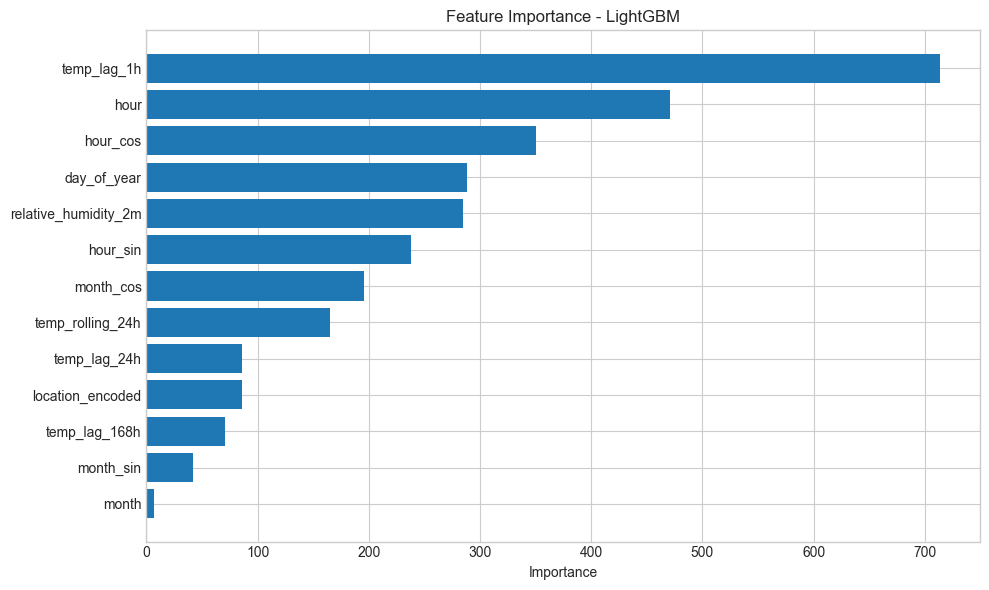

In [23]:
# ## 9. Best Model
best_name = comparison.iloc[0]['Model']
best_result = results[best_name]

print(f"Best Model: {best_name}")
print(f"MAE: {best_result['mae']:.2f}°C")
print(f"RMSE: {best_result['rmse']:.2f}°C")
print(f"R²: {best_result['r2']:.3f}")

# %% [markdown]
# ## 10. Feature Importance

# %%
for name in ['LightGBM', 'XGBoost', 'Random Forest', 'Gradient Boosting']:
    if name in results and hasattr(results[name].get('model'), 'feature_importances_'):
        importance = pd.DataFrame({
            'Feature': feature_cols,
            'Importance': results[name]['model'].feature_importances_
        }).sort_values('Importance', ascending=True)
        
        plt.figure(figsize=(10, 6))
        plt.barh(importance['Feature'], importance['Importance'])
        plt.xlabel('Importance')
        plt.title(f'Feature Importance - {name}')
        plt.tight_layout()
        plt.show()
        break

Using: Random Forest


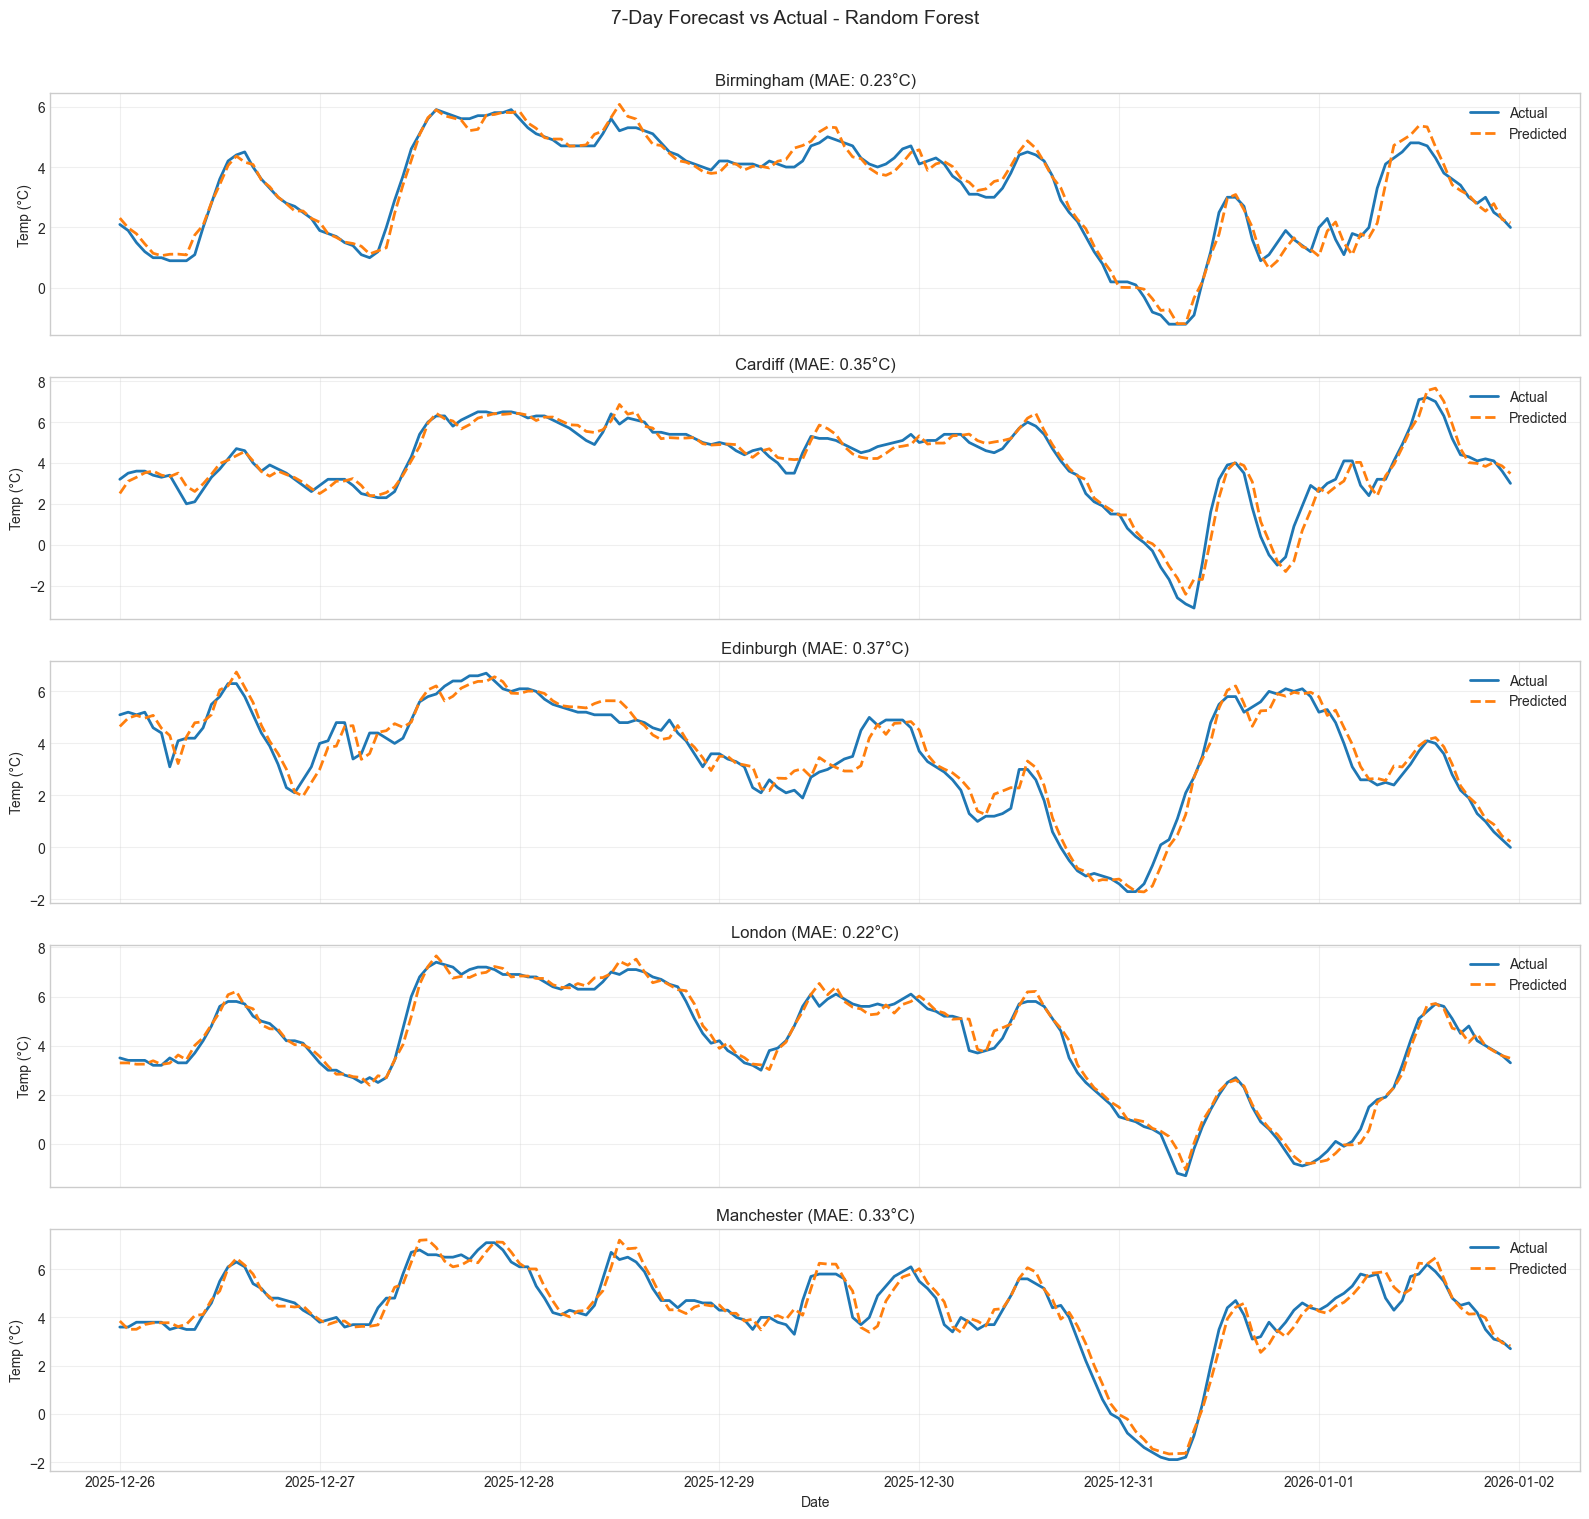

In [37]:
# ## 11. Predictions vs Actuals
best_ml = comparison.iloc[0]['Model']

# If best is SARIMA/Prophet (no hourly predictions), fall back to best ML model
if best_ml in ['SARIMA', 'Prophet']:
    ml_models = comparison[~comparison['Model'].isin(['SARIMA', 'Prophet'])]
    best_ml = ml_models.iloc[0]['Model']

print(f"Using: {best_ml}")

test['predicted'] = results[best_ml]['predictions']
test['error'] = test['predicted'] - test['temperature_2m']

# %%
locations = test['location'].unique()
fig, axes = plt.subplots(len(locations), 1, figsize=(16, 3 * len(locations)), sharex=True)

for i, location in enumerate(locations):
    loc_test = test[test['location'] == location].sort_values('datetime')
    loc_mae = mean_absolute_error(loc_test['temperature_2m'], loc_test['predicted'])
    
    axes[i].plot(loc_test['datetime'], loc_test['temperature_2m'], label='Actual', linewidth=2)
    axes[i].plot(loc_test['datetime'], loc_test['predicted'], label='Predicted', linestyle='--', linewidth=2)
    axes[i].set_title(f'{location} (MAE: {loc_mae:.2f}°C)')
    axes[i].set_ylabel('Temp (°C)')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
plt.suptitle(f'7-Day Forecast vs Actual - {best_ml}', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


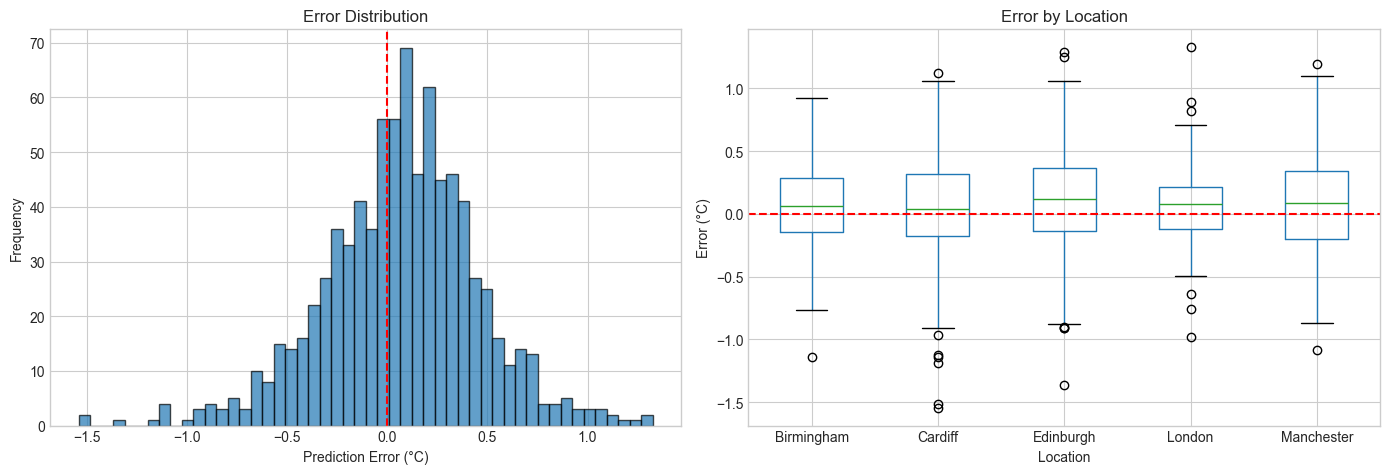

In [25]:
# ## 12. Error Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(test['error'], bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_xlabel('Prediction Error (°C)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Error Distribution')

test.boxplot(column='error', by='location', ax=axes[1])
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Location')
axes[1].set_ylabel('Error (°C)')
axes[1].set_title('Error by Location')
plt.suptitle('')

plt.tight_layout()
plt.show()

Latest data: 2026-01-01 23:00:00
Birmingham: 168 hours predicted
Cardiff: 168 hours predicted
Edinburgh: 168 hours predicted
London: 168 hours predicted
Manchester: 168 hours predicted


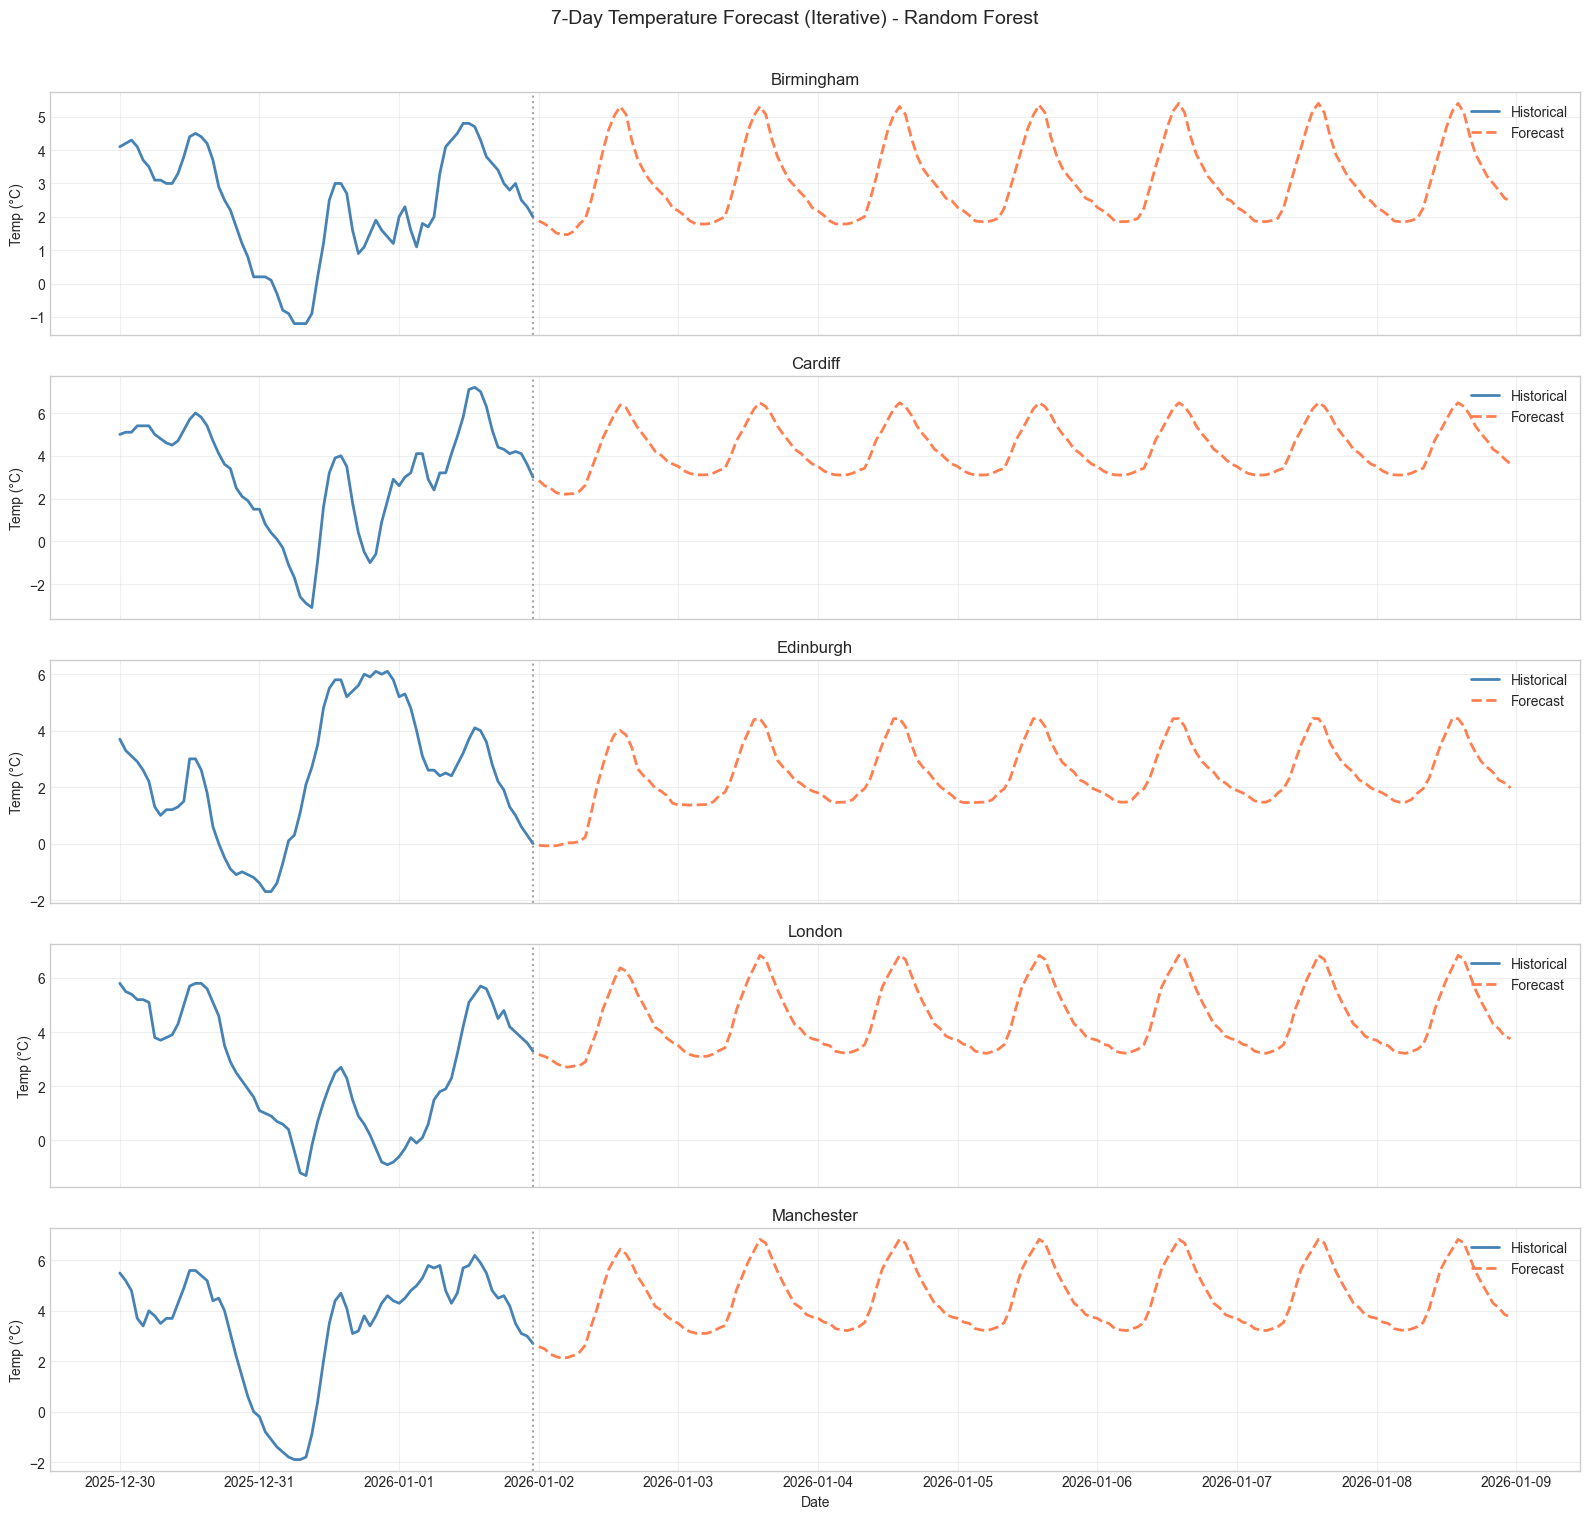

7-Day Forecast Summary (°C)
            Avg  Min  Max
location                 
Birmingham  3.1  1.5  5.4
Cardiff     4.3  2.2  6.5
Edinburgh   2.4 -0.1  4.4
London      4.5  2.7  6.8
Manchester  4.4  2.1  6.8


In [39]:
# %% [markdown]
# ## 16. Forecast Next 7 Days (Iterative)

# %%
from datetime import datetime, timedelta

# Get latest date
latest_date = df['datetime'].max()
print(f"Latest data: {latest_date}")

# Get last 168 hours of actual data per location (for lag features)
history = df.groupby('location').tail(168).copy()

# Forecast settings
forecast_hours = 7 * 24  # 7 days
locations = df['location'].unique()

# Store predictions
all_predictions = []

for location in locations:
    loc_history = history[history['location'] == location].sort_values('datetime').copy()
    loc_predictions = []
    
    # Get location encoding
    loc_encoded = le.transform([location])[0]
    
    # Iteratively predict each hour
    for h in range(forecast_hours):
        future_dt = latest_date + timedelta(hours=h+1)
        
        # Build feature row
        row = {
            'datetime': future_dt,
            'location': location,
            'hour': future_dt.hour,
            'month': future_dt.month,
            'day_of_year': future_dt.timetuple().tm_yday,
            'hour_sin': np.sin(2 * np.pi * future_dt.hour / 24),
            'hour_cos': np.cos(2 * np.pi * future_dt.hour / 24),
            'month_sin': np.sin(2 * np.pi * future_dt.month / 12),
            'month_cos': np.cos(2 * np.pi * future_dt.month / 12),
            'location_encoded': loc_encoded,
            'temp_lag_1h': loc_history['temperature_2m'].iloc[-1],
            'temp_lag_24h': loc_history['temperature_2m'].iloc[-24] if len(loc_history) >= 24 else loc_history['temperature_2m'].iloc[-1],
            'temp_lag_168h': loc_history['temperature_2m'].iloc[-168] if len(loc_history) >= 168 else loc_history['temperature_2m'].iloc[-1],
            'temp_rolling_24h': loc_history['temperature_2m'].tail(24).mean(),
            'relative_humidity_2m': loc_history['relative_humidity_2m'].iloc[-1]
        }
        
        # Predict
        X = pd.DataFrame([row])[feature_cols]
        pred_temp = results[best_ml]['model'].predict(X)[0]
        row['predicted_temp'] = pred_temp
        loc_predictions.append(row)
        
        # Update history with prediction (for next iteration)
        new_row = loc_history.iloc[-1:].copy()
        new_row['datetime'] = future_dt
        new_row['temperature_2m'] = pred_temp
        loc_history = pd.concat([loc_history, new_row]).tail(168)
    
    all_predictions.extend(loc_predictions)
    print(f"{location}: {forecast_hours} hours predicted")

# Create dataframe
future_all = pd.DataFrame(all_predictions)

# %%
# Plot
fig, axes = plt.subplots(len(locations), 1, figsize=(16, 3 * len(locations)), sharex=True)

for i, location in enumerate(locations):
    loc_history = df[df['location'] == location].tail(72).sort_values('datetime')
    loc_future = future_all[future_all['location'] == location].sort_values('datetime')
    
    axes[i].plot(loc_history['datetime'], loc_history['temperature_2m'], 
                 label='Historical', linewidth=2, color='steelblue')
    axes[i].plot(loc_future['datetime'], loc_future['predicted_temp'], 
                 label='Forecast', linewidth=2, linestyle='--', color='coral')
    axes[i].axvline(latest_date, color='grey', linestyle=':', alpha=0.7)
    axes[i].set_title(location)
    axes[i].set_ylabel('Temp (°C)')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
plt.suptitle(f'7-Day Temperature Forecast (Iterative) - {best_ml}', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# %%
# Summary
forecast_summary = future_all.groupby('location')['predicted_temp'].agg(['mean', 'min', 'max']).round(1)
forecast_summary.columns = ['Avg', 'Min', 'Max']
print("7-Day Forecast Summary (°C)")
print(forecast_summary)

# %%
# Save forecast
# future_all[['datetime', 'location', 'predicted_temp']].to_csv(
#     f'{DATA_PATH}future_forecast_7day.csv', index=False
# )
# print("Saved: future_forecast_7day.csv")

In [ ]:
# ## 13. Save Results

# test[['datetime', 'location', 'temperature_2m', 'predicted', 'error']].to_csv(
#     f'{DATA_PATH}forecast_predictions.csv', index=False
# )

# comparison.to_csv(f'{DATA_PATH}model_comparison.csv', index=False)

# print("Saved: forecast_predictions.csv, model_comparison.csv")

Loaded: 263,160 rows
Rows after prep: 262,320
Features: 17
Train: (261480, 17), Test: (840, 17)
Enhanced Model: MAE=0.29°C, R²=0.962


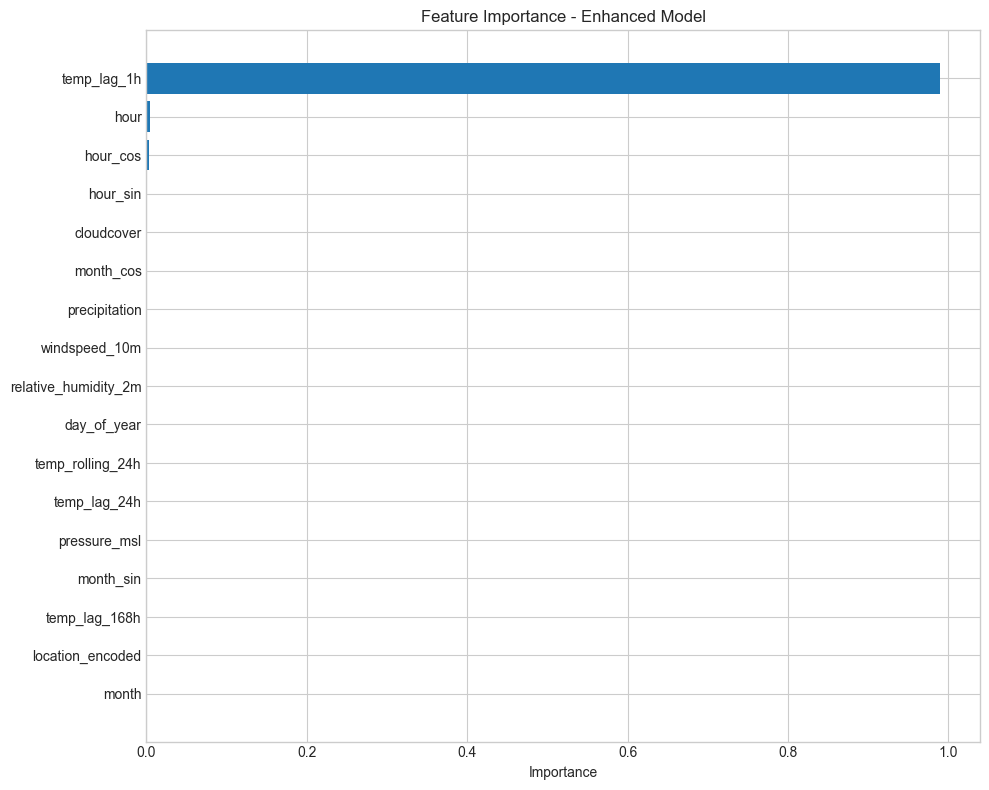

In [44]:
# %% [markdown]
# ## 17. Retrain with Weather Features

# %%
# Reload data with all columns
df = pd.read_csv(f'{DATA_PATH}weather_history_hourly.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['location', 'datetime']).reset_index(drop=True)

print(f"Loaded: {df.shape[0]:,} rows")

# %%
# Feature engineering (same as before)
df['day_of_year'] = df['datetime'].dt.dayofyear
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Lag features
df['temp_lag_1h'] = df.groupby('location')['temperature_2m'].shift(1)
df['temp_lag_24h'] = df.groupby('location')['temperature_2m'].shift(24)
df['temp_lag_168h'] = df.groupby('location')['temperature_2m'].shift(168)
df['temp_rolling_24h'] = df.groupby('location')['temperature_2m'].transform(
    lambda x: x.rolling(24, min_periods=1).mean()
)

# Encode location
le = LabelEncoder()
df['location_encoded'] = le.fit_transform(df['location'])

# Fill missing weather values
weather_cols = ['pressure_msl', 'cloudcover', 'precipitation', 'windspeed_10m']
for col in weather_cols:
    df[col] = df[col].fillna(df[col].mean())

# Drop rows with NaN from lag features
df = df.dropna(subset=['temp_lag_168h'])

print(f"Rows after prep: {df.shape[0]:,}")

# %%
# Enhanced feature list
feature_cols_enhanced = [
    # Time
    'hour', 'month', 'day_of_year',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    
    # Location
    'location_encoded',
    
    # Lag
    'temp_lag_1h', 'temp_lag_24h', 'temp_lag_168h',
    'temp_rolling_24h',
    
    # Weather (NEW)
    'relative_humidity_2m',
    'pressure_msl',
    'cloudcover',
    'precipitation',
    'windspeed_10m',
]

print(f"Features: {len(feature_cols_enhanced)}")

# %%
# Train/test split
split_date = df['date'].max() - timedelta(days=7)

train = df[df['date'] <= split_date]
test = df[df['date'] > split_date]

X_train = train[feature_cols_enhanced]
y_train = train['temperature_2m']
X_test = test[feature_cols_enhanced]
y_test = test['temperature_2m']

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# %%
# Train enhanced model
from sklearn.ensemble import RandomForestRegressor

model_enhanced = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
model_enhanced.fit(X_train, y_train)

y_pred = model_enhanced.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Enhanced Model: MAE={mae:.2f}°C, R²={r2:.3f}")

# %%
# Feature importance
importance = pd.DataFrame({
    'Feature': feature_cols_enhanced,
    'Importance': model_enhanced.feature_importances_
}).sort_values('Importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(importance['Feature'], importance['Importance'])
plt.xlabel('Importance')
plt.title('Feature Importance - Enhanced Model')
plt.tight_layout()
plt.show()

Forecast data: 1680 rows
Date range: 2025-12-31 00:00:00 to 2026-01-08 23:00:00
Latest historical data: 2026-01-01 23:00:00
Future weather rows: 1440
Birmingham: 168 hours predicted
Cardiff: 168 hours predicted
Edinburgh: 168 hours predicted
London: 168 hours predicted
Manchester: 168 hours predicted


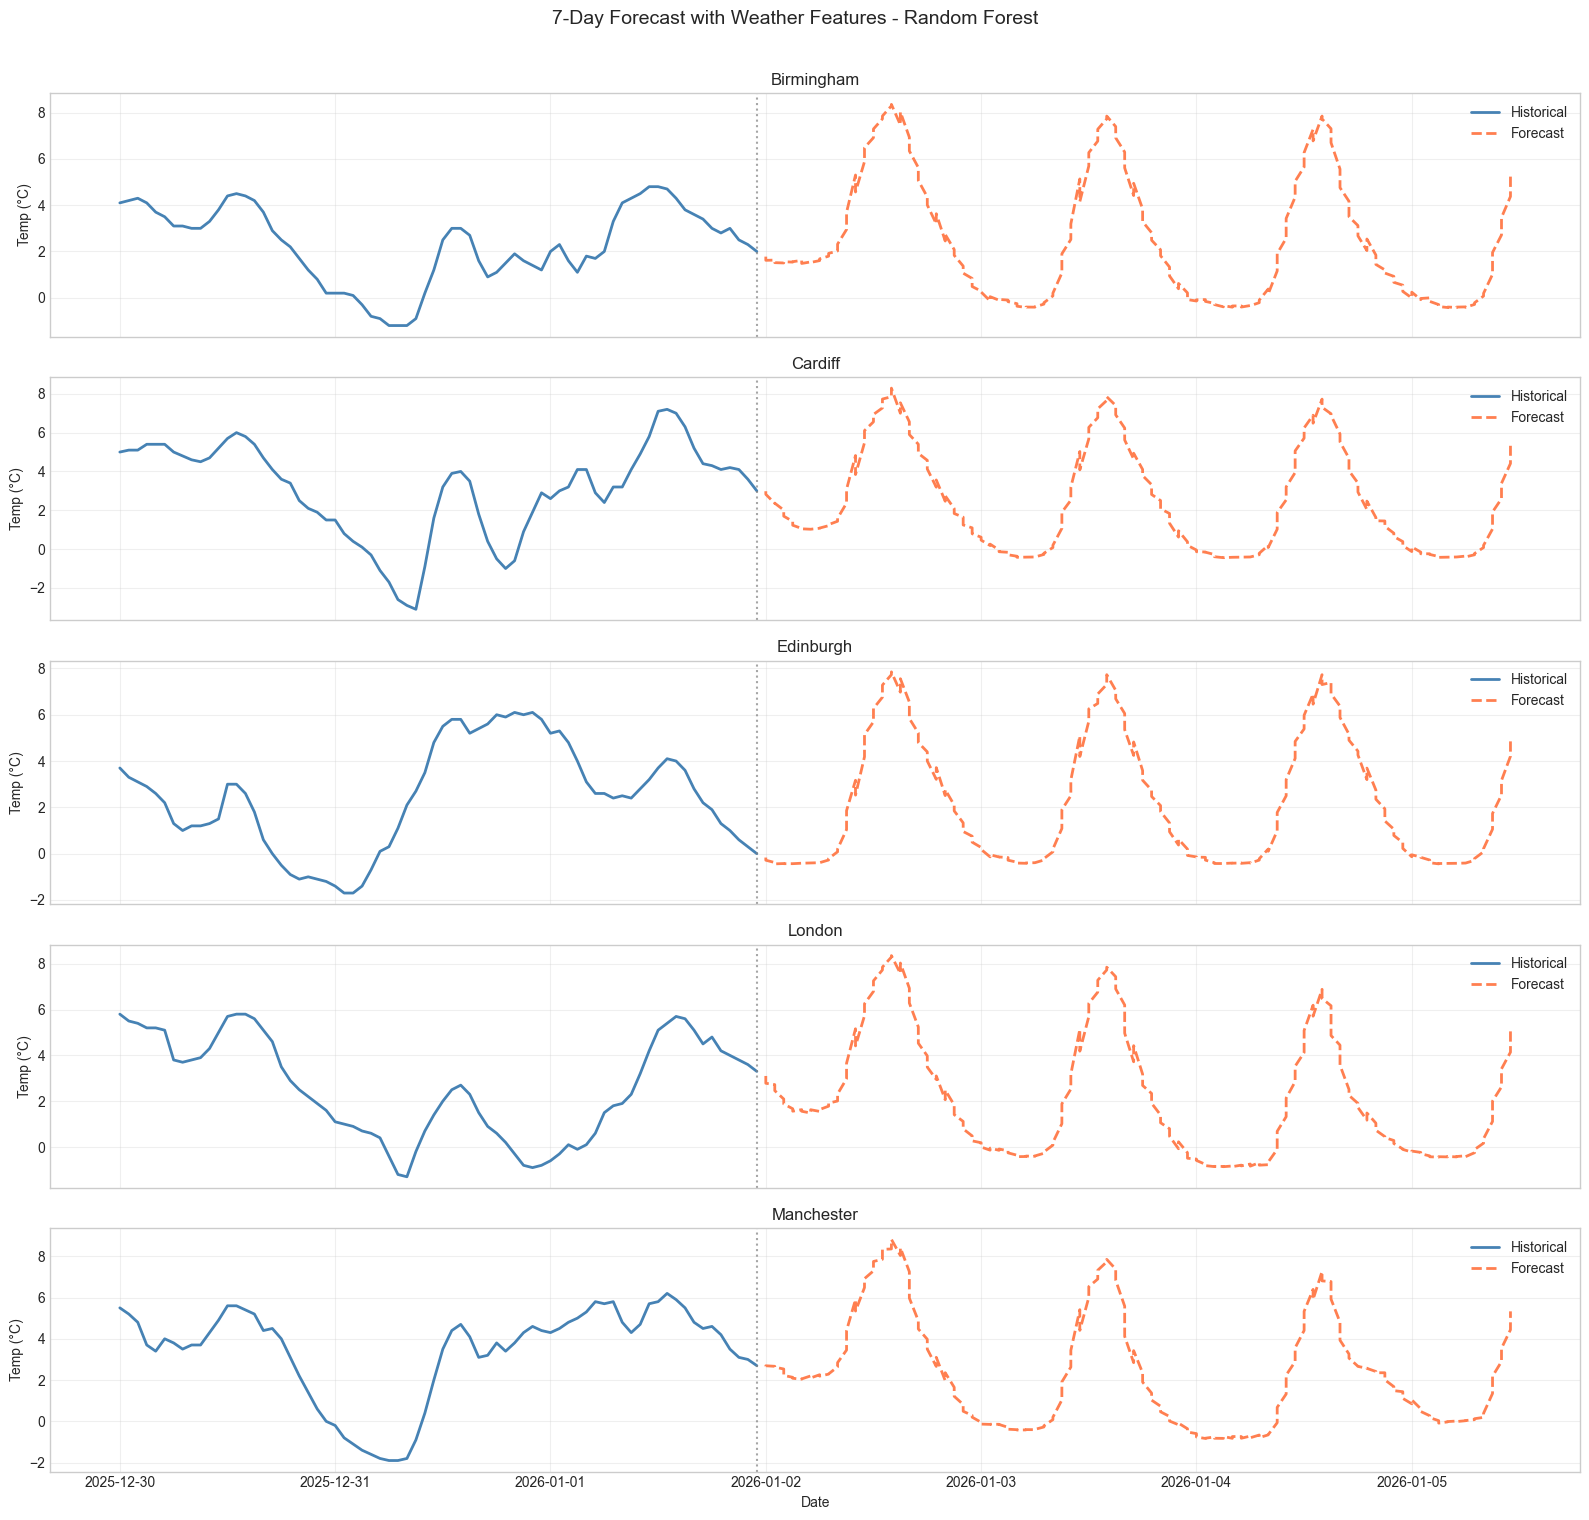

7-Day Forecast Summary
            Avg °C  Min °C  Max °C
location                          
Birmingham     2.4    -0.4     8.4
Cardiff        2.4    -0.4     8.3
Edinburgh      2.1    -0.4     7.9
London         2.1    -0.9     8.4
Manchester     2.3    -0.8     8.8
Saved: forecast_7day_enhanced.csv


In [45]:
# %% [markdown]
# ## 18. 7-Day Forecast with Weather Features

# %%
# Load forecast data (has future weather)
forecast_df = pd.read_csv(f'{DATA_PATH}weather_forecasts_hourly.csv')
forecast_df['datetime'] = pd.to_datetime(forecast_df['datetime'])

print(f"Forecast data: {forecast_df.shape[0]} rows")
print(f"Date range: {forecast_df['datetime'].min()} to {forecast_df['datetime'].max()}")

# %%
# Get latest date from history
latest_date = df['datetime'].max()
print(f"Latest historical data: {latest_date}")

# Filter forecast to future dates only
future_weather = forecast_df[forecast_df['datetime'] > latest_date].copy()
print(f"Future weather rows: {future_weather.shape[0]}")

# %%
# Prepare future dataframe with weather features
locations = df['location'].unique()
forecast_hours = 7 * 24

all_predictions = []

for location in locations:
    # Get location's future weather
    loc_weather = future_weather[future_weather['location'] == location].sort_values('datetime').head(forecast_hours)
    
    # Get last 168 hours of history for lag features
    loc_history = df[df['location'] == location].sort_values('datetime').tail(168).copy()
    
    # Location encoding
    loc_encoded = le.transform([location])[0]
    
    # Iteratively predict
    for idx, weather_row in loc_weather.iterrows():
        future_dt = weather_row['datetime']
        
        row = {
            'datetime': future_dt,
            'location': location,
            
            # Time features
            'hour': future_dt.hour,
            'month': future_dt.month,
            'day_of_year': future_dt.timetuple().tm_yday,
            'hour_sin': np.sin(2 * np.pi * future_dt.hour / 24),
            'hour_cos': np.cos(2 * np.pi * future_dt.hour / 24),
            'month_sin': np.sin(2 * np.pi * future_dt.month / 12),
            'month_cos': np.cos(2 * np.pi * future_dt.month / 12),
            
            # Location
            'location_encoded': loc_encoded,
            
            # Lag features (from history/previous predictions)
            'temp_lag_1h': loc_history['temperature_2m'].iloc[-1],
            'temp_lag_24h': loc_history['temperature_2m'].iloc[-24],
            'temp_lag_168h': loc_history['temperature_2m'].iloc[0],
            'temp_rolling_24h': loc_history['temperature_2m'].tail(24).mean(),
            
            # Weather features (from forecast API)
            'relative_humidity_2m': weather_row['relative_humidity_2m'],
            'pressure_msl': weather_row['pressure_msl'],
            'cloudcover': weather_row['cloudcover'],
            'precipitation': weather_row['precipitation'],
            'windspeed_10m': weather_row['windspeed_10m'],
        }
        
        # Predict
        X = pd.DataFrame([row])[feature_cols_enhanced]
        pred_temp = model_enhanced.predict(X)[0]
        row['predicted_temp'] = pred_temp
        all_predictions.append(row)
        
        # Update history with prediction
        new_row = loc_history.iloc[-1:].copy()
        new_row['datetime'] = future_dt
        new_row['temperature_2m'] = pred_temp
        loc_history = pd.concat([loc_history, new_row]).tail(168)
    
    print(f"{location}: {len(loc_weather)} hours predicted")

future_all = pd.DataFrame(all_predictions)

# %%
# Plot forecast
fig, axes = plt.subplots(len(locations), 1, figsize=(16, 3 * len(locations)), sharex=True)

for i, location in enumerate(locations):
    loc_history = df[df['location'] == location].tail(72).sort_values('datetime')
    loc_future = future_all[future_all['location'] == location].sort_values('datetime')
    
    axes[i].plot(loc_history['datetime'], loc_history['temperature_2m'], 
                 label='Historical', linewidth=2, color='steelblue')
    axes[i].plot(loc_future['datetime'], loc_future['predicted_temp'], 
                 label='Forecast', linewidth=2, linestyle='--', color='coral')
    axes[i].axvline(latest_date, color='grey', linestyle=':', alpha=0.7)
    axes[i].set_title(location)
    axes[i].set_ylabel('Temp (°C)')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
plt.suptitle('7-Day Forecast with Weather Features - Random Forest', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# %%
# Summary
summary = future_all.groupby('location')['predicted_temp'].agg(['mean', 'min', 'max']).round(1)
summary.columns = ['Avg °C', 'Min °C', 'Max °C']
print("7-Day Forecast Summary")
print(summary)

# %%
# Save
future_all[['datetime', 'location', 'predicted_temp', 'pressure_msl', 'cloudcover', 'precipitation']].to_csv(
    f'{DATA_PATH}forecast_7day_enhanced.csv', index=False
)
print("Saved: forecast_7day_enhanced.csv")

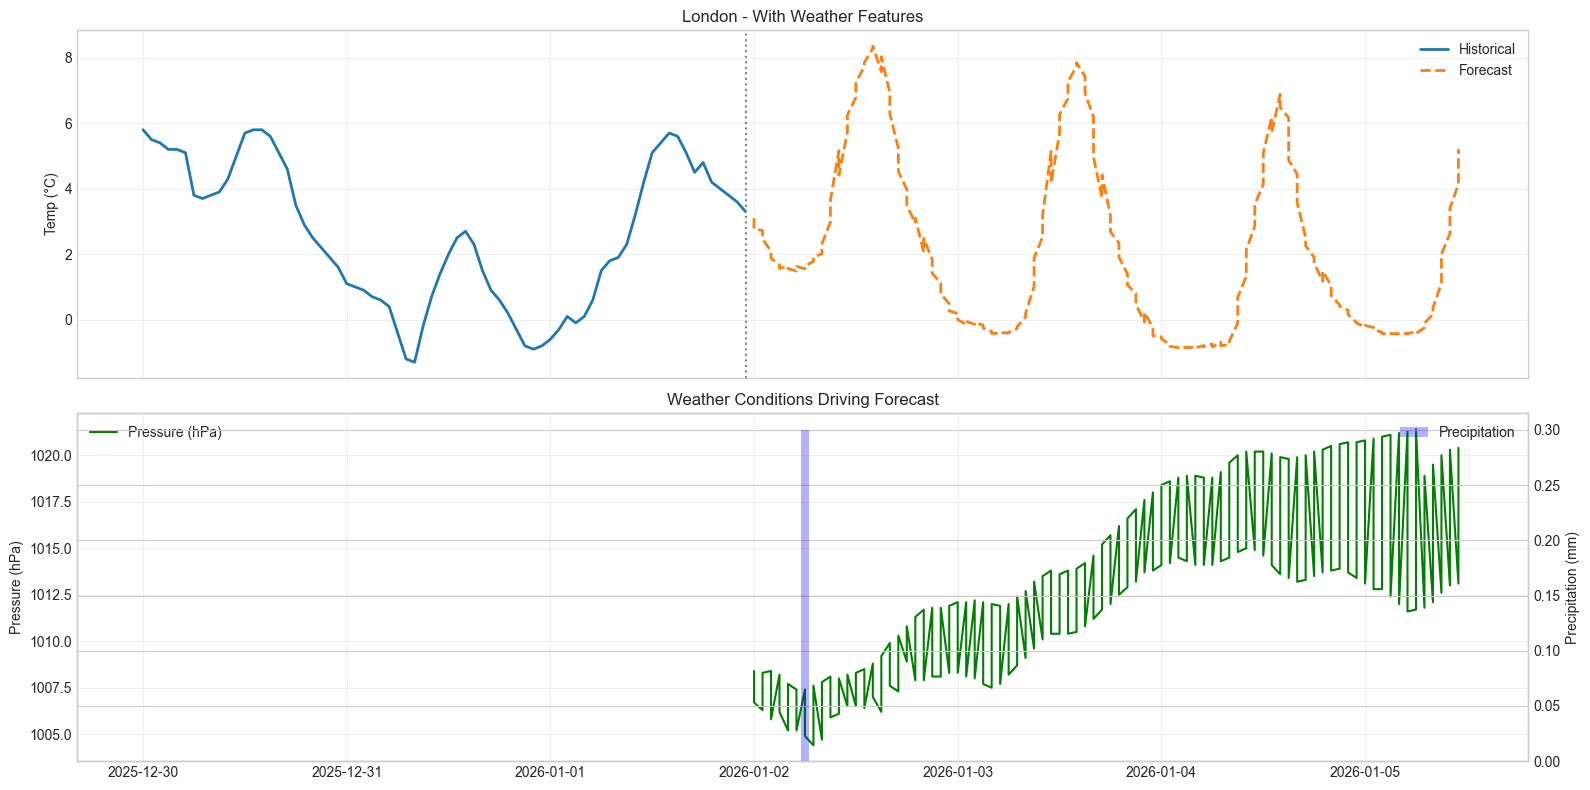

In [54]:
# %%
# Side-by-side comparison
location = 'London'

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

# Without weather (from earlier)
loc_future_basic = future_all_basic[future_all_basic['location'] == location] if 'future_all_basic' in dir() else None

# With weather
loc_future_weather = future_all[future_all['location'] == location].sort_values('datetime')
loc_history = df[df['location'] == location].tail(72).sort_values('datetime')

# Plot with weather
axes[0].plot(loc_history['datetime'], loc_history['temperature_2m'], label='Historical', linewidth=2)
axes[0].plot(loc_future_weather['datetime'], loc_future_weather['predicted_temp'], label='Forecast', linestyle='--', linewidth=2)
axes[0].axvline(latest_date, color='grey', linestyle=':')
axes[0].set_title(f'{location} - With Weather Features')
axes[0].set_ylabel('Temp (°C)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Show weather conditions
axes[1].plot(loc_future_weather['datetime'], loc_future_weather['pressure_msl'], label='Pressure (hPa)', color='green')
ax2 = axes[1].twinx()
ax2.bar(loc_future_weather['datetime'], loc_future_weather['precipitation'], alpha=0.3, label='Precipitation', color='blue', width=0.04)
axes[1].set_title('Weather Conditions Driving Forecast')
axes[1].set_ylabel('Pressure (hPa)')
ax2.set_ylabel('Precipitation (mm)')
axes[1].legend(loc='upper left')
ax2.legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
# %%
# Compare all forecasting methods for Jan 3rd
jan3 = pd.to_datetime('2026-01-03').date()

comparison = pd.DataFrame({
    'Location': ['Birmingham', 'Cardiff', 'Edinburgh', 'London', 'Manchester']
})

# API Forecast
api_jan3 = future_api[future_api['datetime'].dt.date == jan3].groupby('location')['temperature_2m'].agg(['min', 'max'])
comparison['API Min'] = comparison['Location'].map(api_jan3['min'])
comparison['API Max'] = comparison['Location'].map(api_jan3['max'])

# ML Model
model_jan3 = future_all[future_all['datetime'].dt.date == jan3].groupby('location')['predicted_temp'].agg(['min', 'max'])
comparison['ML Min'] = comparison['Location'].map(model_jan3['min'])
comparison['ML Max'] = comparison['Location'].map(model_jan3['max'])

# Climatology
comparison['Clim Min'] = [3.1, 4.1, 3.9, 3.5, 3.5]
comparison['Clim Max'] = [5.8, 7.4, 5.8, 7.0, 6.3]

# Persistence
comparison['Pers Min'] = [1.1, 2.4, 0.0, -0.6, 2.7]
comparison['Pers Max'] = [4.8, 7.2, 5.3, 5.7, 6.2]

# BBC Actual (London only)
comparison['Actual Min'] = [None, None, None, -4.0, None]
comparison['Actual Max'] = [None, None, None, 3.0, None]

print("Jan 3rd Forecast Comparison")
print(comparison.round(1).to_string(index=False))

Jan 3rd Forecast Comparison
  Location  API Min  API Max  ML Min  ML Max  Clim Min  Clim Max  Pers Min  Pers Max  Actual Min  Actual Max
Birmingham     -1.2      2.5    -0.4     7.9       3.1       5.8       1.1       4.8         NaN         NaN
   Cardiff     -1.4      5.2    -0.4     7.9       4.1       7.4       2.4       7.2         NaN         NaN
 Edinburgh     -1.4      1.7    -0.4     7.7       3.9       5.8       0.0       5.3         NaN         NaN
    London     -1.1      2.5    -0.5     7.9       3.5       7.0      -0.6       5.7        -4.0         3.0
Manchester     -2.1      1.9    -0.5     7.9       3.5       6.3       2.7       6.2         NaN         NaN


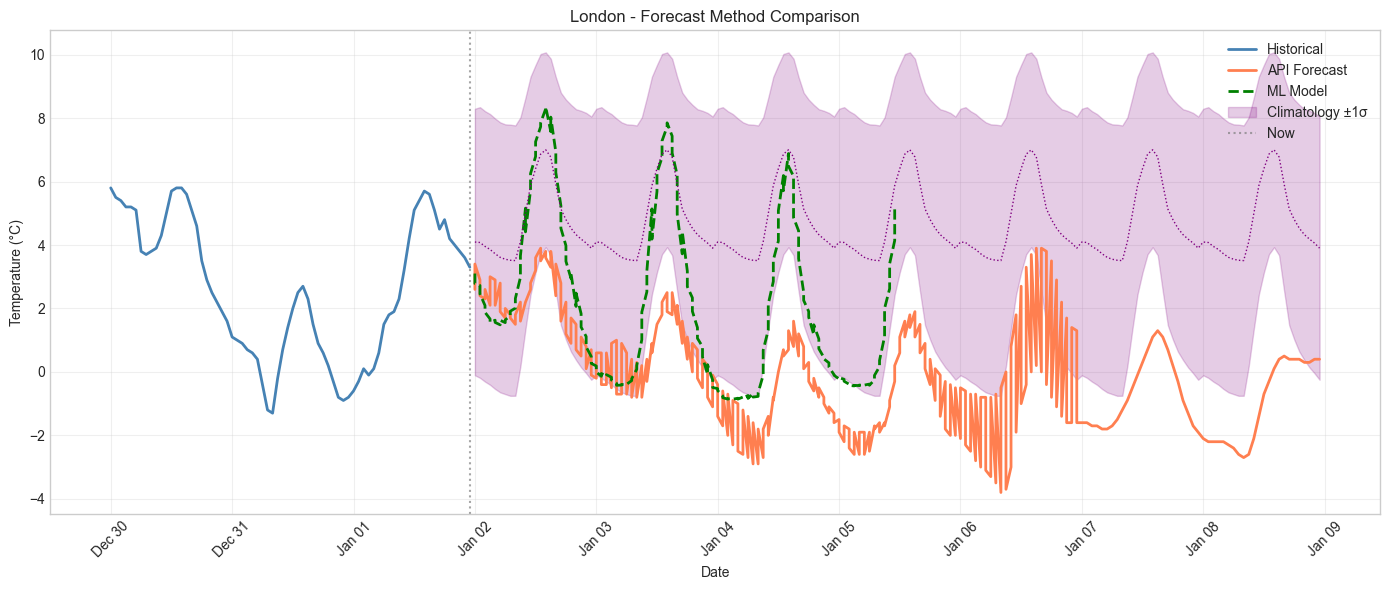

In [64]:
# %%
# Plot all methods for London
location = 'London'

fig, ax = plt.subplots(figsize=(14, 6))

# Historical
loc_history = df[df['location'] == location].tail(72).sort_values('datetime')
ax.plot(loc_history['datetime'], loc_history['temperature_2m'], 
        label='Historical', linewidth=2, color='steelblue')

# API Forecast
loc_api = future_api[future_api['location'] == location].sort_values('datetime')
ax.plot(loc_api['datetime'], loc_api['temperature_2m'], 
        label='API Forecast', linewidth=2, color='coral')

# ML Model
loc_ml = future_all[future_all['location'] == location].sort_values('datetime')
ax.plot(loc_ml['datetime'], loc_ml['predicted_temp'], 
        label='ML Model', linewidth=2, linestyle='--', color='green')

# Climatology (as band)
loc_clim = future_clim[future_clim['location'] == location].sort_values('datetime')
ax.fill_between(loc_clim['datetime'], 
                loc_clim['clim_mean'] - loc_clim['clim_std'],
                loc_clim['clim_mean'] + loc_clim['clim_std'],
                alpha=0.2, color='purple', label='Climatology ±1σ')
ax.plot(loc_clim['datetime'], loc_clim['clim_mean'], 
        linewidth=1, linestyle=':', color='purple')

ax.axvline(latest_date, color='grey', linestyle=':', alpha=0.7, label='Now')
ax.set_title(f'{location} - Forecast Method Comparison')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (°C)')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

# Format x-axis
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()